# nuScenes LiDAR Detection with MMDetection3D

This tutorial evaluates a PointPillars LiDAR 3D object-detection model on the nuScenes `v1.0-mini` split using PerceptionMetrics. It covers loading the dataset, wrapping an MMDetection3D model, inspecting predictions in bird's-eye view, and evaluating the model.

It expects the nuScenes mini dataset in `examples/local/nuscenes/v1.0-mini` and a PointPillars config and checkpoint in `examples/local/model/nuscenes_pointpillars`.

In [1]:
from copy import copy
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from mmdet3d.apis import init_model

from perceptionmetrics.datasets.nuScenes import NuScenesLiDARDetectionDataset
from perceptionmetrics.models.torch_detection import TorchLiDARDetectionModel

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "perceptionmetrics").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

LOCAL_DIR = PROJECT_ROOT / "examples" / "local"
DATASET_DIR = LOCAL_DIR / "nuscenes" / "v1.0-mini"
MODEL_DIR = LOCAL_DIR / "model" / "nuscenes_pointpillars"
MMDET_CONFIG = MODEL_DIR / "pointpillars_hv_fpn_sbn-all_8xb4-2x_nus-3d.py"
CHECKPOINT = MODEL_DIR / "hv_pointpillars_fpn_sbn-all_4x8_2x_nus-3d_20210826_104936-fca299c1.pth"
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"

if not DATASET_DIR.is_dir() or not MMDET_CONFIG.is_file() or not CHECKPOINT.is_file():
    raise FileNotFoundError("Download the nuScenes mini dataset and PointPillars checkpoint to examples/local first.")

dataset = NuScenesLiDARDetectionDataset(
    dataset_dir=str(DATASET_DIR),
    version="v1.0-mini",
    split="val",
)
print(f"Validation samples: {len(dataset.dataset)}")

/home/tejass/miniconda3/envs/pm/lib/python3.11/site-packages/torch/cuda/__init__.py:107: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at ../c10/cuda/CUDAFunctions.cpp:109.)
  return torch._C._cuda_getDeviceCount() > 0


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


/home/tejass/miniconda3/envs/pm/lib/python3.11/site-packages/torchvision/datapoints/__init__.py:12: UserWarning: The torchvision.datapoints and torchvision.transforms.v2 namespaces are still Beta. While we do not expect major breaking changes, some APIs may still change according to user feedback. Please submit any feedback you may have in this issue: https://github.com/pytorch/vision/issues/6753, and you can also check out https://github.com/pytorch/vision/issues/7319 to learn more about the APIs that we suspect might involve future changes. You can silence this warning by calling torchvision.disable_beta_transforms_warning().
  warnings.warn(_BETA_TRANSFORMS_WARNING)
/home/tejass/miniconda3/envs/pm/lib/python3.11/site-packages/torchvision/transforms/v2/__init__.py:54: UserWarning: The torchvision.datapoints and torchvision.transforms.v2 namespaces are still Beta. While we do not expect major breaking changes, some APIs may still change according to user feedback. Please submit any fe

Tensorflow not available
Validation samples: 81


## PerceptionMetrics Model Metadata

The nuScenes adapter maps raw nuScenes categories to the ten detection classes used by the downloaded PointPillars checkpoint.

In [2]:
MODEL_CONFIG_PATH = LOCAL_DIR / "nuscenes_pointpillars_model_config.json"
MODEL_ONTOLOGY_PATH = LOCAL_DIR / "nuscenes_pointpillars_ontology.json"

model_config = {
    "model_format": "mmdet3d",
    "confidence_threshold": 0.5,
    "iou_threshold": 0.5,
}

MODEL_CONFIG_PATH.write_text(json.dumps(model_config, indent=2))
MODEL_ONTOLOGY_PATH.write_text(json.dumps(dataset.ontology, indent=2))
print(dataset.ontology)

{'car': {'idx': 0, 'rgb': [0, 0, 0]}, 'truck': {'idx': 1, 'rgb': [0, 0, 0]}, 'trailer': {'idx': 2, 'rgb': [0, 0, 0]}, 'bus': {'idx': 3, 'rgb': [0, 0, 0]}, 'construction_vehicle': {'idx': 4, 'rgb': [0, 0, 0]}, 'bicycle': {'idx': 5, 'rgb': [0, 0, 0]}, 'motorcycle': {'idx': 6, 'rgb': [0, 0, 0]}, 'pedestrian': {'idx': 7, 'rgb': [0, 0, 0]}, 'traffic_cone': {'idx': 8, 'rgb': [0, 0, 0]}, 'barrier': {'idx': 9, 'rgb': [0, 0, 0]}}


## Load the MMDetection3D Model

MMDetection3D builds PointPillars from its Python configuration and restores the downloaded checkpoint. `TorchLiDARDetectionModel` then provides the standard PerceptionMetrics inference and evaluation interface.

In [3]:
mmdet3d_model = init_model(
    config=str(MMDET_CONFIG),
    checkpoint=str(CHECKPOINT),
    device=DEVICE,
)

model = TorchLiDARDetectionModel(
    model=mmdet3d_model,
    model_cfg=str(MODEL_CONFIG_PATH),
    ontology_fname=str(MODEL_ONTOLOGY_PATH),
    device=torch.device(DEVICE),
)

/home/tejass/miniconda3/envs/pm/lib/python3.11/site-packages/mmdet3d/models/dense_heads/anchor3d_head.py:94: UserWarning: dir_offset and dir_limit_offset will be depressed and be incorporated into box coder in the future
  warnings.warn(
/home/tejass/miniconda3/envs/pm/lib/python3.11/site-packages/mmdet3d/apis/inference.py:109: UserWarning: Don't suggest using CPU device. Some functions are not supported for now.
  warnings.warn('Don\'t suggest using CPU device. '


Loads checkpoint by local backend from path: /home/tejass/Downloads/TUDELFT_ROBOTICS/GSOC/gsoc2026-Tejas_Stanley/PerceptionMetrics/examples/local/model/nuscenes_pointpillars/hv_pointpillars_fpn_sbn-all_4x8_2x_nus-3d_20210826_104936-fca299c1.pth
Open3D-ML3D not available


## Inspect One Sample

Point clouds use `x, y, z, intensity` features. Ground-truth and predicted boxes use `[x, y, z, dx, dy, dz, yaw]` in the LiDAR coordinate frame. The bird's-eye-view plot compares ground truth with predictions above the configured confidence threshold.

Sample: 3e8750f331d7499e9b5123e9eb70f2e2
Points: (34752, 4)
Ground-truth boxes: 23
Predicted boxes: 6


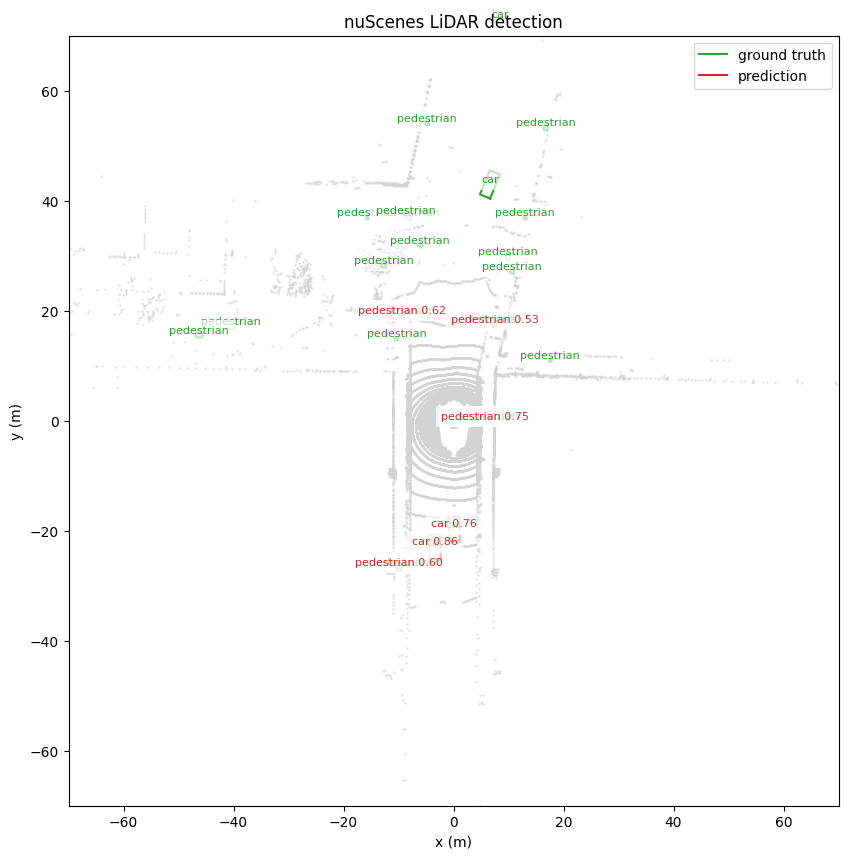

In [9]:
def draw_bev_box(ax, box, color, text=None):
    x, y, _, dx, dy, _, yaw = box
    corners = np.array(
        [
            [-dx / 2, -dy / 2],
            [dx / 2, -dy / 2],
            [dx / 2, dy / 2],
            [-dx / 2, dy / 2],
            [-dx / 2, -dy / 2],
        ]
    )
    rotation = np.array(
        [[np.cos(yaw), -np.sin(yaw)], [np.sin(yaw), np.cos(yaw)]]
    )
    corners = corners @ rotation.T + np.array([x, y])
    ax.plot(corners[:, 0], corners[:, 1], color=color, linewidth=1.5)
    if text:
        ax.text(
            x,
            y,
            text,
            color=color,
            fontsize=8,
            ha="center",
            va="bottom",
            bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none"},
        )

sample_id = dataset.dataset.index[0]
row = dataset.dataset.loc[sample_id]
points = dataset.read_points(row["points"])
gt_boxes, gt_labels = dataset.read_annotation(row["annotation"])
prediction = model.predict(points)

print(f"Sample: {sample_id}")
print(f"Points: {points.shape}")
print(f"Ground-truth boxes: {len(gt_boxes)}")
print(f"Predicted boxes: {len(prediction['boxes_3d'])}")

BEV_RANGE_METERS = 70

fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(points[:, 0], points[:, 1], c="lightgray", s=0.2)
class_names = {class_data["idx"]: class_name for class_name, class_data in dataset.ontology.items()}
for box, label in zip(gt_boxes, gt_labels):
    draw_bev_box(ax, box, "tab:green", class_names[int(label)])
for box, label, score in zip(
    prediction["boxes_3d"].numpy(),
    prediction["labels"].numpy(),
    prediction["scores"].numpy(),
):
    draw_bev_box(ax, box, "tab:red", f"{class_names[int(label)]} {score:.2f}")
ax.set_aspect("equal")
ax.set_xlim(-BEV_RANGE_METERS, BEV_RANGE_METERS)
ax.set_ylim(-BEV_RANGE_METERS, BEV_RANGE_METERS)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("nuScenes LiDAR detection")
ax.legend(
    handles=[
        plt.Line2D([], [], color="tab:green", label="ground truth"),
        plt.Line2D([], [], color="tab:red", label="prediction"),
    ]
)
plt.show()

## Evaluate



In [8]:
IOU_MODES = ("3d", "bev")

# Use a small subset for a quick tutorial run.
eval_dataset = copy(dataset)

from IPython.display import Markdown, display
import matplotlib.pyplot as plt

for iou_mode in IOU_MODES:
    results = model.eval(
        dataset=eval_dataset,
        split="val",
        iou_mode=iou_mode,
        predictions_outdir=str(
            LOCAL_DIR / f"nuscenes_pointpillars_predictions_{iou_mode}"
        ),
    )

    display(
        Markdown(
            f"### {iou_mode.upper()} IoU Detection Metrics "
            f"(threshold = {model.model_cfg.get('iou_threshold', 0.5):.2f})"
        )
    )
    display(results["metrics_df"])



  0%|          | 0/81 [00:00<?, ?it/s]

### 3D IoU Detection Metrics (threshold = 0.50)

,car,truck,trailer,bus,construction_vehicle,bicycle,motorcycle,pedestrian,traffic_cone,barrier,mean
AP,0.361417,0.177033,NaN,0.454545,NaN,0.0,0.022727,0.090909,0.0,NaN,0.158090
Precision,0.936803,0.875000,NaN,0.909091,NaN,0.0,0.166667,0.763158,0.0,NaN,0.521531
Recall,0.392523,0.169355,NaN,0.487805,NaN,0.0,0.003861,0.064065,0.0,NaN,0.159658
TP,1008.000000,21.000000,NaN,20.000000,NaN,0.0,1.000000,87.000000,0.0,NaN,162.428571
FP,68.000000,3.000000,NaN,2.000000,NaN,0.0,5.000000,27.000000,0.0,NaN,15.000000
FN,1560.000000,103.000000,NaN,21.000000,NaN,52.0,258.000000,1271.000000,39.0,NaN,472.000000
mAP@[0.5:0.95],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.077564
AUC-PR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.251251


  0%|          | 0/81 [00:00<?, ?it/s]

### BEV IoU Detection Metrics (threshold = 0.50)

,car,truck,trailer,bus,construction_vehicle,bicycle,motorcycle,pedestrian,traffic_cone,barrier,mean
AP,0.449355,0.177033,NaN,0.541322,NaN,0.0,0.090909,0.090909,0.0,NaN,0.192790
Precision,0.955390,0.875000,NaN,0.954545,NaN,0.0,1.000000,0.859649,0.0,NaN,0.663512
Recall,0.400312,0.169355,NaN,0.512195,NaN,0.0,0.023166,0.072165,0.0,NaN,0.168170
TP,1028.000000,21.000000,NaN,21.000000,NaN,0.0,6.000000,98.000000,0.0,NaN,167.714286
FP,48.000000,3.000000,NaN,1.000000,NaN,0.0,0.000000,16.000000,0.0,NaN,9.714286
FN,1540.000000,103.000000,NaN,20.000000,NaN,52.0,253.000000,1260.000000,39.0,NaN,466.714286
mAP@[0.5:0.95],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.112081
AUC-PR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.261229
